# 15 Construir un panel de siniestros en Barcelona

**Pregunta del panel.** ¿Qué zonas y franjas conviene revisar primero durante un periodo concreto? Vamos a combinar tres gráficos del día 1 con un indicador. El filtro de distrito y meses se aplica una sola vez. Todas las vistas responden a la misma selección.

## 0 · Abrir y preparar

Abre el notebook en Jupyter, VS Code o Colab. En el repositorio, el CSV está en `PySpark/data`. En Colab, súbelo desde **Archivos** con su nombre original. Si faltan bibliotecas, ejecuta `%pip install pandas "seaborn>=0.13" matplotlib`. Los controles interactivos del final usan `ipywidgets` y son opcionales.

## 1 · Recuperar el csv del inicio del [notebook 14](14_visualizacion_siniestros.ipynb)

Cargamos el CSV generado en ese notebook para que se pueda abrir por separado [siniestros](../data/2023_accidents_causa_conductor_gu_bcn_siniestros.csv). Comprobamos la coherencia y dejamos una fila por expediente. La categoría de distrito desconocido se conserva.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [15]:

sns.set_theme(style="whitegrid")

ruta = '../data/2023_accidents_causa_conductor_gu_bcn_siniestros.csv'

siniestros = pd.read_csv(ruta)
siniestros.head()

,expedient,districte,barri,torn,year,month,day,hora,latitud,longitud,data,dia_setmana,mes
0,2023S000699,Desconegut,Desconegut,Tarda,2023,2,4,16,41.413783,2.166596,2023-02-04,Dissabte,2023-02-01
1,2023S005197,Desconegut,Desconegut,Matí,2023,9,1,13,41.430598,2.155015,2023-09-01,Divendres,2023-09-01
2,2023S007430,Desconegut,Desconegut,Matí,2023,12,15,11,41.413783,2.166596,2023-12-15,Divendres,2023-12-01
3,2023S000961,Desconegut,Desconegut,Tarda,2023,1,28,14,41.423762,2.172596,2023-01-28,Dissabte,2023-01-01
4,2023S006486,Desconegut,Desconegut,Tarda,2023,11,2,14,41.399587,2.124189,2023-11-02,Dijous,2023-11-01


In [16]:
siniestros.columns

Index(['expedient', 'districte', 'barri', 'torn', 'year', 'month', 'day',
       'hora', 'latitud', 'longitud', 'data', 'dia_setmana', 'mes'],
      dtype='object')

In [18]:
siniestros['dia_setmana'].unique()

array(['Dissabte', 'Divendres', 'Dijous', 'Dilluns', 'Diumenge',
       'Dimecres', 'Dimarts'], dtype=object)

In [20]:
print(f"Expedientes distintos: {len(siniestros):,}")
print(f"Expedientes con distrito desconocido: {siniestros['districte'].eq('Desconocido').sum():,}")
siniestros[['districte', 'barri', 'data', 'hora', 'torn']].head()

Expedientes distintos: 7,721
Expedientes con distrito desconocido: 0


,districte,barri,data,hora,torn
0,Desconegut,Desconegut,2023-02-04,16,Tarda
1,Desconegut,Desconegut,2023-09-01,13,Matí
2,Desconegut,Desconegut,2023-12-15,11,Matí
3,Desconegut,Desconegut,2023-01-28,14,Tarda
4,Desconegut,Desconegut,2023-11-02,14,Tarda


## 2 · Filtrar antes de calcular

El distrito y el rango de meses definen qué expedientes entran. De esa misma tabla salen:

- El **indicador**, que cuenta los expedientes seleccionados.
- La **línea**, que muestra el recuento mensual dentro del periodo.
- Las **barras**, que comparan distritos cuando eliges todos. Si eliges un distrito, comparan sus barrios.
- El **mapa de calor**, que cruza día de la semana y hora.

Incluimos meses y horas con cero expedientes en la selección. Si no hay ningún expediente, el panel lo indica.

In [21]:
siniestros['mes'].unique()

array(['2023-02-01', '2023-09-01', '2023-12-01', '2023-01-01',
       '2023-11-01', '2023-05-01', '2023-07-01', '2023-08-01',
       '2023-06-01', '2023-04-01', '2023-03-01', '2023-10-01'],
      dtype=object)

In [22]:
siniestros['month'].unique()

array([ 2,  9, 12,  1, 11,  5,  7,  8,  6,  4,  3, 10])

In [23]:
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
todos = 'Todos los distritos'

def resumir_panel(distrito, primer_mes, ultimo_mes):
    seleccion = siniestros[siniestros['data'].dt.month.between(primer_mes, ultimo_mes)]
    zona = 'districte' if distrito == todos else 'barri'
    if distrito != todos:
        seleccion = seleccion[seleccion['districte'] == distrito]

    tendencia = (seleccion.groupby(seleccion['data'].dt.month).size()
                 .reindex(range(primer_mes, ultimo_mes + 1), fill_value=0))
    zonas = seleccion[zona].value_counts()
    calor = (pd.crosstab(seleccion['dia_semana'], seleccion['hora'])
             .reindex(index=dias, columns=range(24), fill_value=0))
    total = len(seleccion)
    assert total == tendencia.sum() == zonas.sum() == calor.to_numpy().sum()
    return total, tendencia, zonas, calor, zona

## 3 · Dibujar el panel

Usamos subplots para colocar tres gráficos en una sola figura. El título indica qué estás viendo y el recuento aparece arriba. El mapa de calor conserva el orden de los días y las 24 horas. Al cambiar la selección se recalculan los tres gráficos. La comprobación del paso anterior verifica que todos cuentan el mismo total. La escala de color se adapta a la selección. Para comparar dos paneles, lee los recuentos de sus escalas.

In [24]:
def mostrar_panel(distrito=todos, primer_mes=1, ultimo_mes=12):
    total, tendencia, zonas, calor, zona = resumir_panel(distrito, primer_mes, ultimo_mes)
    periodo = f'{meses[primer_mes - 1]} a {meses[ultimo_mes - 1]} de 2023'
    if primer_mes == ultimo_mes:
        periodo = f'{meses[primer_mes - 1]} de 2023'
    if total == 0:
        print(f'{distrito} · {periodo} · 0 expedientes registrados')
        return

    fig, axes = plt.subplot_mosaic([['mes', 'zona'], ['hora', 'hora']], figsize=(12, 8))
    fig.suptitle(f'{distrito} · {periodo} · {total:,} expedientes', fontsize=15)

    sns.lineplot(x=tendencia.index, y=tendencia.values, marker='o', ax=axes['mes'])
    axes['mes'].set(title='Evolución mensual', xlabel='Mes', ylabel='Expedientes')
    axes['mes'].set_xticks(tendencia.index, [meses[m - 1][:3] for m in tendencia.index])

    sns.barplot(x=zonas.values, y=zonas.index, color='#613A89', ax=axes['zona'])
    axes['zona'].set(title=f'Recuento por {zona}', xlabel='Expedientes', ylabel='')

    sns.heatmap(calor, cmap='Blues', cbar_kws={'label': 'Expedientes'}, ax=axes['hora'])
    axes['hora'].set(title='Día de la semana y hora', xlabel='Hora del día', ylabel='')
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

mostrar_panel()

AttributeError: Can only use .dt accessor with datetimelike values

## 4 · Cambiar la selección y comprobar el resultado

Primero mira todos los distritos. Después limita la vista a Eixample y al primer semestre. Comprueba qué cambia en el indicador, la línea y el mapa de calor. Las barras ahora muestran barrios. El panel anual mantiene la opción «Desconocido» para revisar qué expedientes carecen de distrito.

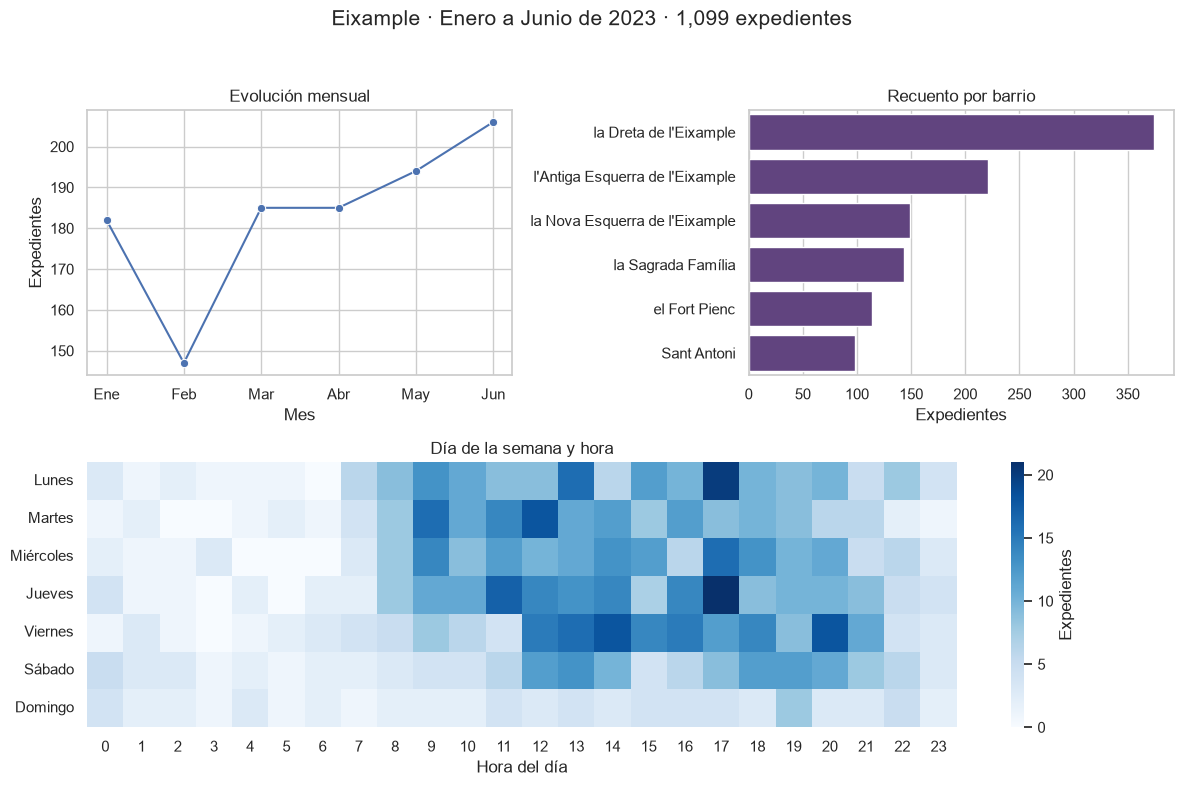

In [6]:
mostrar_panel(distrito='Eixample', primer_mes=1, ultimo_mes=6)

## 5 · Añadir controles interactivos

Los controles llaman a la misma función que acabamos de probar. Si tu entorno admite widgets, podrás elegir un distrito y mover el intervalo de meses sin editar el código. Si falta la biblioteca, instala `ipywidgets` con `%pip install ipywidgets` o sigue usando la función del paso 4.

In [7]:
try:
    import ipywidgets as widgets
    from IPython.display import display
except ImportError:
    print('Puedes usar el panel del paso 4 sin controles interactivos.')
else:
    selector = widgets.Dropdown(
        options=[todos] + sorted(siniestros['distrito'].unique()), description='Distrito',
    )
    rango = widgets.SelectionRangeSlider(
        options=list(zip(meses, range(1, 13))), index=(0, 11),
        description='Meses', continuous_update=False,
    )

    def actualizar(distrito, periodo):
        mostrar_panel(distrito, *periodo)

    salida = widgets.interactive_output(actualizar, {'distrito': selector, 'periodo': rango})
    display(widgets.VBox([selector, rango, salida]))

## 6 · Exportar la tabla que usaremos en las otras versiones

Una fila de la tabla exportada representa una combinación de fecha, distrito, barrio y hora. La columna `expedientes` guarda cuántos siniestros hay en esa combinación. Para recuperar el total hay que **sumar** esa columna. Los notebooks 16 y 17 usarán el mismo archivo.

Ejecuta esta celda para guardar `resumen_siniestros_panel.csv` junto al CSV original. En el repositorio, quedará en `PySpark/data`. En Colab aparecerá en **Archivos**.

In [10]:
tabla_panel = (siniestros.groupby(['fecha', 'distrito', 'barrio', 'hora'])
               .size().rename('expedientes').reset_index())
assert tabla_panel['expedientes'].sum() == len(siniestros)

destino = '../data/resumen_siniestros_panel.csv'
tabla_panel.to_csv(destino, index=False, encoding='utf-8-sig')
print(f'Tabla guardada en {destino}')
tabla_panel.head()

Tabla guardada en ../data/resumen_siniestros_panel.csv


,fecha,distrito,barrio,hora,expedientes
0,2023-01-01,Ciutat Vella,el Raval,3,1
1,2023-01-01,Gràcia,la Vila de Gràcia,14,1
2,2023-01-01,Gràcia,la Vila de Gràcia,17,2
3,2023-01-01,Horta-Guinardó,el Baix Guinardó,3,1
4,2023-01-01,Horta-Guinardó,la Vall d'Hebron,20,1


## Cierre · Usar el panel para decidir qué revisar

1. Elige un distrito y un periodo. Anota la selección, el total y la franja que destaca.
2. Compara esa selección con otro periodo del mismo distrito. ¿Qué se mantiene? ¿Qué cambia? Si los periodos tienen diferente duración, compara también expedientes por día.
3. Explica qué expedientes revisarías primero y qué información pedirías para comparar el riesgo. El recuento muestra lo registrado. La exposición al tráfico es una de las piezas que faltan.

En el día 3 usaremos esa propuesta para discutir cómo medir si una decisión aporta valor.

[Siguiente: Streamlit y Dash](16_panel_streamlit_y_dash.ipynb) · [Día 3: Power BI](17_power_bi_y_valor.ipynb) · [Volver al README](../README.md) · [Día 1: galería de visualizaciones](14_visualizacion_siniestros.ipynb) · [Controles de Jupyter](https://ipywidgets.readthedocs.io/en/stable/examples/Using%20Interact.html)